# Apnea-ECG inference: the CinC 2018 models

Runs the inference service's two CinC 2018 models, `model_cinc2018_float32.tflite` and
`model_cinc2018_int8.tflite` (in `services/inference/data/models/`), on every night of PhysioNet's
Apnea-ECG database, and compares each minute with the expert's label.

Apnea-ECG holds 70 nights of 70 people (a01 to a20, b01 to b05, c01 to c10, x01 to x35): a
single-lead ECG at 100 Hz and one expert label per minute, apnea or normal. Neither model was
trained, validated or tested on any of them. Each model gets the threshold the service gives it
(`MODEL_THRESHOLDS` in `.env`) and the service's 5-minute smoothing, so the decisions here are the
ones the service gives.

Run the cells in order. The Dataset cell downloads what `data/apnea-ecg/` is missing and builds the
set once; the figures and `scores.json` go to `results/inference/`.

## Setup

In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
# Hides TensorFlow's C++ INFO and WARNING lines. Must be set BEFORE tensorflow
# is imported; errors still show.

import hashlib                   # SHA-256 of every download, checked against PhysioNet's list
import http.client               # HTTPException: a transfer cut off mid-way
import json                      # the list of nights, scores.json
import time                      # waits between two download attempts
import urllib.request            # downloads from PhysioNet
import warnings
from concurrent.futures import ThreadPoolExecutor   # the two models side by side
from pathlib import Path         # paths that work the same on macOS, Linux and Windows

import matplotlib.pyplot as plt  # every figure
import numpy as np               # arrays: the ECG windows, labels and predictions
import tensorflow as tf          # tf.lite.Interpreter runs the .tflite files
import wfdb                      # PhysioNet's library: reads recordings and their annotations
from matplotlib.colors import ListedColormap                           # shades of the confusion matrices
from scipy.signal import butter, filtfilt, iirnotch, sosfiltfilt       # band-pass and notch filters
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve   # AUC and its curves

tf.get_logger().setLevel("ERROR")
warnings.filterwarnings("ignore", message=".*tf.lite.Interpreter is deprecated.*")
# tf.lite.Interpreter still works; TensorFlow only announces that it will move
# to the separate LiteRT package.

# ── folders ──────────────────────────────────────────────────────────────────
ROOT = Path.cwd().parent if Path.cwd().name == "training" else Path.cwd()
# The project root, whichever folder the kernel starts in. VS Code starts a
# notebook's kernel in the notebook's own folder (training/), a terminal-launched
# Jupyter usually at the root; both resolve to the same place.

APNEA_DIR = ROOT / "data" / "apnea-ecg"                            # PhysioNet's files: .hea, .dat, .apn
PROCESSED_DIR = ROOT / "data" / "processed"                        # the set built by the Dataset cell
MODELS_DIR = ROOT / "services" / "inference" / "data" / "models"   # the service's .tflite files
OUT_DIR = ROOT / "results" / "inference"                           # this notebook's figures and scores
for folder in (APNEA_DIR, PROCESSED_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ── the set ──────────────────────────────────────────────────────────────────
SET = "apnea-ecg"           # the files are X_apnea-ecg.npy, y_apnea-ecg.npy, ...
RECORDS = ([f"a{i:02d}" for i in range(1, 21)] + [f"b{i:02d}" for i in range(1, 6)]
           + [f"c{i:02d}" for i in range(1, 11)] + [f"x{i:02d}" for i in range(1, 36)])
# The 70 nights with an ECG and expert labels. a01r to c03r hold some of the
# same nights again, with breathing signals, and are not read.
FS = 100                    # the models' sampling rate, which is also Apnea-ECG's
WINDOW_SAMPLES = 60 * FS    # one minute = one expert label = one prediction

# ── the models and the service's settings ────────────────────────────────────
MODEL_FILES = ("model_cinc2018_float32.tflite", "model_cinc2018_int8.tflite")   # in MODELS_DIR
ENV = ROOT / ".env" if (ROOT / ".env").exists() else ROOT / ".env.example"
settings = dict(line.split("=", 1) for line in ENV.read_text().splitlines()
                if "=" in line and not line.startswith("#"))
# The service's settings file, NAME=value per line; .env.example when there
# is no .env.
thresholds = {name.strip(): float(value) for name, value in
              (pair.split("=", 1) for pair in settings["MODEL_THRESHOLDS"].split(",") if pair.strip())}
# "a.tflite=0.4,b.tflite=0.5" -> {"a.tflite": 0.4, "b.tflite": 0.5}, read as
# services/inference/source/app.py reads it.
missing = [m for m in MODEL_FILES if m not in thresholds]
assert not missing, f"MODEL_THRESHOLDS in {ENV.name} has no threshold for {missing}"
MODELS = {m: thresholds[m] for m in MODEL_FILES}
# File -> its threshold: a minute is apnea when its smoothed probability is above it.
SMOOTH_WINDOW = int(settings.get("SMOOTH_WINDOW", "5"))   # minutes averaged into each decision
print(f"{ENV.name}: " + ", ".join(f"{m} {t:.2f}" for m, t in MODELS.items())
      + f", {SMOOTH_WINDOW}-minute smoothing")
NAMES = {model: model.removeprefix("model_cinc2018_").removesuffix(".tflite") for model in MODELS}
# Short names for the tables and figures: "float32", "int8".

# ── figures ──────────────────────────────────────────────────────────────────
BLUE, CORAL = "#0184FF", "#ff6a6a"     # the series colours, in this order
INK, INK_2, MUTED, RULE, SURFACE = "#141212", "#181d21", "#9aa5b1", "#e8ecef", "#ffffff"
COLORS = dict(zip(MODELS, (BLUE, CORAL)))                 # float32 blue, int8 coral
SHADES = ListedColormap(["#D3E8FD", BLUE])
# Confusion-matrix cells: light blue below half of the row, BLUE from half up.
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": RULE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=[BLUE, CORAL]),
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.major.size": 0, "ytick.major.size": 0,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
    "savefig.dpi": 150, "savefig.bbox": "tight"})
# One look for every figure: a light surface, with the axes and grid in light
# grey behind the data. A line drawn without a colour takes BLUE, the next one CORAL.

.env: model_cinc2018_float32.tflite 0.41, model_cinc2018_int8.tflite 0.51, 5-minute smoothing


## Dataset

Downloads each file of the 70 nights that `data/apnea-ecg/` does not have yet, from PhysioNet's
copy on Amazon S3 (physionet.org as a fallback), checked against PhysioNet's SHA-256 list where it
has an entry (x01.apn to x35.apn have none):

- `.hea`: text header, sampling rate and scaling
- `.dat`: the ECG
- `.apn`: the expert's labels, one per minute

Each night then goes through the inference service's preprocessing
(`services/inference/source/pipeline.py`), the same as the training notebook's: band-pass 0.5 to
40 Hz, 50 Hz notch, clip to +-5 mV, cut into one-minute windows, z-score each window. Apnea-ECG is
already at 100 Hz, so there is nothing to resample. Only the minutes the expert labelled are kept.
The set, in `data/processed/`, in the training notebook's format:

- `X_apnea-ecg.npy` (minutes, 6000) float16, `y_apnea-ecg.npy` (minutes,): 1 apnea, 0 normal
- `night_apnea-ecg.npy` (minutes,): the index of the window's night in `nights_apnea-ecg.json`

A night's windows are consecutive rows, in time order. The set is built once, and again only when
one of its files is missing.

In [2]:
# ── download what is missing ─────────────────────────────────────────────────
URLS = ["https://physionet-open.s3.amazonaws.com/apnea-ecg/1.0.0/"] * 3 + [
    "https://physionet.org/files/apnea-ecg/1.0.0/"]
# Tried in this order until one works: PhysioNet's copy on Amazon S3 three
# times, then physionet.org.


def fetch(name: str) -> bytes:
    problem = None
    for attempt, base in enumerate(URLS):
        if attempt:
            time.sleep(5 * attempt)
        try:
            with urllib.request.urlopen(base + name, timeout=60) as response:
                return response.read()
        except (OSError, http.client.HTTPException) as error:
            problem = error
    raise OSError(f"{name}: {problem}")
    # Each failed attempt waits 5 s longer than the one before.


missing = [f"{r}{ext}" for r in RECORDS for ext in (".hea", ".dat", ".apn")
           if not (APNEA_DIR / f"{r}{ext}").exists()]
if missing:
    checksums = {name: digest for digest, name in
                 (line.split() for line in fetch("SHA256SUMS.txt").decode().splitlines() if line.strip())}
    # Each line is "<sha256> <file name>".
    for name in missing:
        data = fetch(name)
        if name in checksums and hashlib.sha256(data).hexdigest() != checksums[name]:
            raise OSError(f"{name}: the download does not match PhysioNet's checksum")
        part = APNEA_DIR / f"{name}.part"
        part.write_bytes(data)
        part.replace(APNEA_DIR / name)
        # Written under another name and renamed once complete, so an
        # interrupted run never leaves half a file behind.
    print(f"downloaded {len(missing)} files")


# ── preprocessing: the service's ─────────────────────────────────────────────
EPS = 1e-6
CLIP_MV = 5.0


def clean_ecg(x: np.ndarray) -> np.ndarray:
    """A whole night of raw ECG (mV) -> filtered and clipped, same length."""
    x = sosfiltfilt(butter(4, [0.5, 40], btype="band", fs=FS, output="sos"), x)   # keeps 0.5-40 Hz
    x = filtfilt(*iirnotch(50, Q=30, fs=FS), x)                                  # removes 50 Hz
    x = np.nan_to_num(x, nan=np.nanmedian(x))                                    # a missing sample -> the median
    return np.clip(x, -CLIP_MV, CLIP_MV)                                         # bounds artifacts at +-5 mV
    # Both filters run forward then backward, so their phase shifts cancel and
    # the heartbeats do not move in time.


def to_windows(ecg_clean: np.ndarray) -> np.ndarray:
    """Whole minutes from the start of the recording -> (N, 6000) float32, each z-scored."""
    n = len(ecg_clean) // WINDOW_SAMPLES
    w = ecg_clean[:n * WINDOW_SAMPLES].astype(np.float32).reshape(n, WINDOW_SAMPLES)
    w = (w - w.mean(axis=1, keepdims=True)) / (w.std(axis=1, keepdims=True) + EPS)
    return np.nan_to_num(w, nan=0.0, posinf=0.0, neginf=0.0)
    # Each minute minus its own mean, divided by its own standard deviation.
    # EPS avoids a division by zero on a flat minute. A trailing partial minute
    # is dropped.
# The two functions compute what services/inference/source/pipeline.py
# computes, minus its resampling, which leaves a 100 Hz recording unchanged.


# ── labels and windows of one night ──────────────────────────────────────────
def expert_labels(record: str) -> np.ndarray:
    """Per whole minute of the recording: 1 apnea, 0 normal, -1 no label."""
    path = str(APNEA_DIR / record)
    header = wfdb.rdheader(path)
    assert header.fs == FS, f"{record} is sampled at {header.fs} Hz"
    labels = np.full(header.sig_len // WINDOW_SAMPLES, -1, dtype=np.int8)
    ann = wfdb.rdann(path, "apn")
    for sample, symbol in zip(ann.sample, ann.symbol):
        if sample // WINDOW_SAMPLES < len(labels):
            labels[sample // WINDOW_SAMPLES] = symbol == "A"
    return labels
    # The .apn file has one annotation per minute, on the minute's first
    # sample: "A" apnea, "N" normal. A label past the last whole minute has no
    # window and is dropped.


def night_windows(record: str, labels: np.ndarray):
    ecg = wfdb.rdrecord(str(APNEA_DIR / record)).p_signal[:, 0]     # the ECG in mV
    keep = np.flatnonzero(labels >= 0)
    return to_windows(clean_ecg(ecg))[keep].astype(np.float16), labels[keep].astype(np.float32)
    # Only the minutes the expert labelled.


# ── the set ──────────────────────────────────────────────────────────────────
set_files = [PROCESSED_DIR / name for name in (f"X_{SET}.npy", f"y_{SET}.npy",
                                               f"night_{SET}.npy", f"nights_{SET}.json")]
x_path, y_path, night_path, list_path = set_files

if all(f.exists() for f in set_files) and json.loads(list_path.read_text()) == RECORDS:
    print("set: already built")
else:
    for f in set_files:
        f.unlink(missing_ok=True)
    labels = {r: expert_labels(r) for r in RECORDS}
    sizes = [int((labels[r] >= 0).sum()) for r in RECORDS]
    offsets = np.concatenate([[0], np.cumsum(sizes)])
    X = np.lib.format.open_memmap(x_path, mode="w+", dtype=np.float16,
                                  shape=(int(offsets[-1]), WINDOW_SAMPLES))
    y = np.zeros(int(offsets[-1]), dtype=np.float32)
    for i, r in enumerate(RECORDS):
        X[offsets[i]:offsets[i + 1]], y[offsets[i]:offsets[i + 1]] = night_windows(r, labels[r])
    X.flush()
    del X
    np.save(y_path, y)
    np.save(night_path, np.repeat(np.arange(len(RECORDS), dtype=np.int32), sizes))
    list_path.write_text(json.dumps(RECORDS))
    # The window count of every night is known from its labels before any
    # window is computed, so X is created at its final size directly on disk
    # (open_memmap) and each night writes its own rows. The list of nights is
    # written last: an interrupted build is redone from the start.

y = np.load(y_path)
nights = json.loads(list_path.read_text())
print(f"{SET}: {len(y):,} minutes from {len(nights)} nights, {y.mean():.1%} apnea, "
      f"{x_path.stat().st_size / 1e6:.0f} MB")

set: already built
apnea-ecg: 34,271 minutes from 70 nights, 38.1% apnea, 411 MB


## Models

Runs each model on every minute of the set, one window at a time, as the service does. The int8
model gets the window quantised to int8 and returns an int8 that is turned back into a
probability; the float32 model takes the window and returns the probability as they are. The
probabilities are then smoothed within each night, over `SMOOTH_WINDOW` minutes, and compared with
the threshold.

In [3]:
X = np.load(PROCESSED_DIR / f"X_{SET}.npy", mmap_mode="r")
y = np.load(PROCESSED_DIR / f"y_{SET}.npy").astype(int)
night = np.load(PROCESSED_DIR / f"night_{SET}.npy")
nights = json.loads((PROCESSED_DIR / f"nights_{SET}.json").read_text())
assert len(X) == len(y) == len(night), "the set's arrays disagree"
# mmap_mode="r": X stays on disk and only the rows asked for are read.
missing = [m for m in MODELS if not (MODELS_DIR / m).exists()]
assert not missing, f"not in {MODELS_DIR}: {missing}"


def predict(model: str) -> np.ndarray:
    """P(apnea) for every window of X, one window at a time."""
    interpreter = tf.lite.Interpreter(
        model_path=str(MODELS_DIR / model),
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    # Plain built-in kernels, as in the service: the desktop XNNPACK delegate
    # cannot prepare the int8 graph.
    interpreter.allocate_tensors()
    inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    quantized = inp["dtype"] == np.int8
    in_scale, in_zero = inp["quantization"]
    out_scale, out_zero = out["quantization"]
    # An int8 tensor maps whole numbers to real values with two constants:
    # real = scale x (q - zero_point). A float32 model reports (0.0, 0).
    probs = np.empty(len(X), dtype=np.float32)
    for i in range(len(X)):
        x = X[i].astype(np.float32)[np.newaxis, :, np.newaxis]     # (1, 6000, 1)
        if quantized:
            x = np.clip(np.round(x / in_scale) + in_zero, -128, 127).astype(np.int8)
            # Real value -> int8; np.clip keeps a rare extreme sample inside
            # the int8 range instead of wrapping around.
        interpreter.set_tensor(inp["index"], x)
        interpreter.invoke()
        raw = interpreter.get_tensor(out["index"])[0, 0]
        probs[i] = (int(raw) - out_zero) * out_scale if quantized else raw
        # int8 -> probability; int(...) first, so the subtraction cannot
        # overflow the int8 type.
    return probs


def smooth(prob: np.ndarray, night: np.ndarray) -> np.ndarray:
    """Centred moving average over SMOOTH_WINDOW minutes, within each night separately."""
    out = np.empty_like(prob)
    starts = np.flatnonzero(np.diff(night, prepend=-1))
    for a, b in zip(starts, np.append(starts[1:], len(prob))):
        padded = np.pad(prob[a:b], SMOOTH_WINDOW // 2, mode="edge")
        out[a:b] = np.convolve(padded, np.ones(SMOOTH_WINDOW) / SMOOTH_WINDOW, mode="valid")
    return out
    # A new night starts where the night index changes. np.pad repeats the
    # edge values so the first and last minutes of a night are averaged over a
    # full window, and two nights are never averaged together.


with ThreadPoolExecutor(max_workers=len(MODELS)) as pool:
    raw = dict(zip(MODELS, pool.map(predict, MODELS)))
# One thread per model, each with its own interpreter. invoke() releases
# Python's lock while it runs, so the two models run at the same time.
prob = {m: smooth(raw[m], night) for m in MODELS}                        # what the threshold is applied to
apnea = {m: (prob[m] > threshold).astype(int) for m, threshold in MODELS.items()}   # 1 apnea, 0 normal

print(f"{len(y):,} minutes from {len(nights)} nights, {y.mean():.1%} apnea")
for m in MODELS:
    print(f"  {NAMES[m]:8s} {apnea[m].mean():.1%} of the minutes called apnea")

34,271 minutes from 70 nights, 38.1% apnea
  float32  41.1% of the minutes called apnea
  int8     39.6% of the minutes called apnea


## Scores

Every minute the expert labelled, for each model:

- **TN** normal minute called normal, **FP** normal called apnea, **FN** apnea called normal,
  **TP** apnea called apnea
- **accuracy**: share of minutes called right
- **sensitivity**: share of apnea minutes caught, TP / (TP + FN)
- **specificity**: share of normal minutes left alone, TN / (TN + FP)
- **precision**: share of the minutes called apnea that were apnea, TP / (TP + FP)
- **F1**: the harmonic mean of precision and sensitivity
- **AUC**: how often an apnea minute gets a higher probability than a normal one, over every
  threshold at once; **raw AUC** is the same before smoothing

Rows: all 70 nights; the 35 x nights, which `make eval` scores through the service; the 35 a, b
and c nights; then the nights grouped by the expert's total of apnea minutes, as `make demo` groups
them: apnea (100 or more), borderline (5 to 99), control (under 5). The scores, every night's
included, are saved to `results/inference/scores.json`.

In [4]:
names = np.array(nights)[night]                                        # each minute's night
expert_minutes = np.bincount(night, weights=y, minlength=len(nights)).astype(int)   # per night
CLASSES = {"apnea": (100, np.inf), "borderline": (5, 100), "control": (0, 5)}
# Group -> (lowest, highest) number of apnea minutes, the highest excluded.


def night_class(apnea_minutes: float) -> str:
    return next(c for c, (low, high) in CLASSES.items() if low <= apnea_minutes < high)


expert_class = np.array([night_class(m) for m in expert_minutes])     # one per night
SUBSETS = {
    "all 70 nights": np.ones(len(y), dtype=bool),
    "x01-x35": np.char.startswith(names, "x"),
    "a01-c10": ~np.char.startswith(names, "x"),
    **{f"{c} nights": expert_class[night] == c for c in CLASSES},
}
# Each subset is a mask over the minutes.


def scores(y: np.ndarray, p: np.ndarray, a: np.ndarray, p_raw: np.ndarray) -> dict:
    """Expert labels, smoothed probabilities, decisions and raw probabilities of some minutes -> scores."""
    tn, fp, fn, tp = (int(((y == expert) & (a == model)).sum())
                      for expert, model in ((0, 0), (0, 1), (1, 0), (1, 1)))
    both = 0 < y.sum() < len(y)
    return {"minutes": int(len(y)), "apnea_share": float(y.mean()),
            "accuracy": (tp + tn) / len(y),
            "sensitivity": tp / (tp + fn) if tp + fn else None,
            "specificity": tn / (tn + fp) if tn + fp else None,
            "precision": tp / (tp + fp) if tp + fp else None,
            "f1": 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else None,
            "auc": float(roc_auc_score(y, p)) if both else None,
            "auc_raw": float(roc_auc_score(y, p_raw)) if both else None,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    # A score whose denominator is empty is None: a night without apnea
    # minutes has no sensitivity and no AUC.


results = {}
for model, threshold in MODELS.items():
    results[model] = {"threshold": threshold}
    for subset, rows in SUBSETS.items():
        results[model][subset] = scores(y[rows], prob[model][rows], apnea[model][rows], raw[model][rows])
    results[model]["per night"] = {
        r: scores(y[night == i], prob[model][night == i], apnea[model][night == i], raw[model][night == i])
        for i, r in enumerate(nights)}
(OUT_DIR / "scores.json").write_text(json.dumps(results, indent=1))


def show(value, spec: str, width: int) -> str:
    return f"{'n/a' if value is None else format(value, spec):>{width}s}"


print(f"{'':17s} {'nights':>6s} {'minutes':>7s} {'apnea':>6s}  {'model':7s} {'accuracy':>8s} "
      f"{'sensitivity':>11s} {'specificity':>11s} {'precision':>9s} {'F1':>5s} {'AUC':>5s} "
      f"{'raw AUC':>7s} {'TN':>6s} {'FP':>6s} {'FN':>6s} {'TP':>6s}")
for subset, rows in SUBSETS.items():
    for k, model in enumerate(MODELS):
        s = results[model][subset]
        lead = (f"{subset:17s} {len(np.unique(night[rows])):6d} {s['minutes']:7,d} {s['apnea_share']:6.1%}"
                if k == 0 else " " * 39)
        print(f"{lead}  {NAMES[model]:7s} {s['accuracy']:8.1%} {show(s['sensitivity'], '.3f', 11)} "
              f"{show(s['specificity'], '.3f', 11)} {show(s['precision'], '.3f', 9)} "
              f"{show(s['f1'], '.3f', 5)} {show(s['auc'], '.3f', 5)} {show(s['auc_raw'], '.3f', 7)} "
              f"{s['TN']:6,d} {s['FP']:6,d} {s['FN']:6,d} {s['TP']:6,d}")
print("\nthresholds: " + ", ".join(f"{NAMES[m]} {t:.2f}" for m, t in MODELS.items()))
print(f"saved {(OUT_DIR / 'scores.json').relative_to(ROOT)}")

                  nights minutes  apnea  model   accuracy sensitivity specificity precision    F1   AUC raw AUC     TN     FP     FN     TP
all 70 nights         70  34,271  38.1%  float32    91.3%       0.925       0.905     0.857 0.890 0.970   0.949 19,206  2,007    985 12,073
                                         int8       90.3%       0.892       0.910     0.859 0.875 0.963   0.933 19,295  1,918  1,406 11,652
x01-x35               35  17,248  38.0%  float32    92.0%       0.944       0.905     0.859 0.900 0.974   0.952  9,688  1,013    366  6,181
                                         int8       90.9%       0.911       0.909     0.859 0.884 0.966   0.934  9,722    979    584  5,963
a01-c10               35  17,023  38.2%  float32    90.5%       0.905       0.905     0.856 0.880 0.967   0.947  9,518    994    619  5,892
                                         int8       89.7%       0.874       0.911     0.858 0.866 0.961   0.932  9,573    939    822  5,689
apnea nights        

## Confusion matrices

All 70 nights. Rows are the expert, columns the model. Each cell is shaded by its share of its
row: the top row splits the normal minutes, the bottom row the apnea minutes.

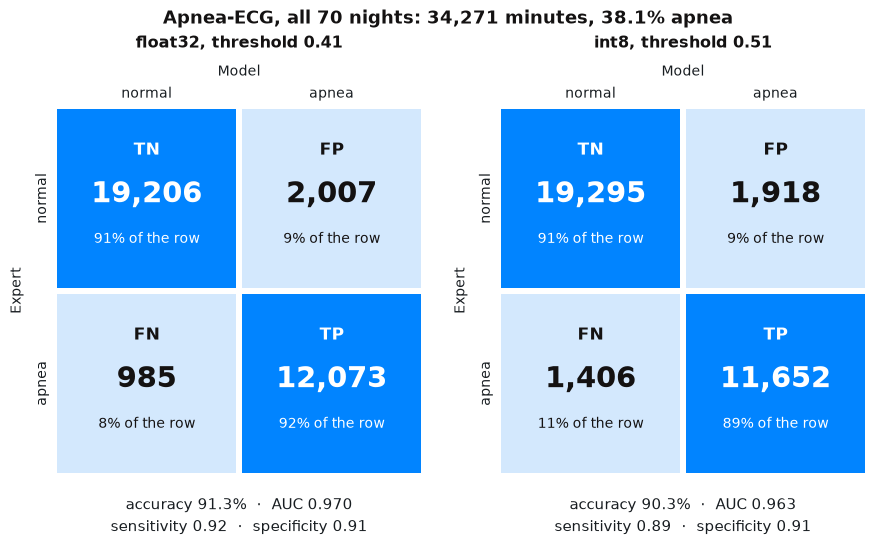

In [5]:
TAGS = (("TN", "FP"), ("FN", "TP"))
fig, axes = plt.subplots(1, len(MODELS), figsize=(10.5, 5.8))
for ax, (model, threshold) in zip(axes, MODELS.items()):
    s = results[model]["all 70 nights"]
    grid = np.array([[s["TN"], s["FP"]], [s["FN"], s["TP"]]])
    share = grid / grid.sum(axis=1, keepdims=True)
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j + 0.015, i + 0.015), 0.97, 0.97, color=SHADES(share[i, j]),
                                       linewidth=0))
            text = "white" if share[i, j] > 0.5 else INK
            ax.text(j + 0.5, i + 0.24, TAGS[i][j], ha="center", va="center", color=text,
                    fontsize=12, fontweight="bold")
            ax.text(j + 0.5, i + 0.48, f"{grid[i, j]:,}", ha="center", va="center", color=text,
                    fontsize=21, fontweight="bold")
            ax.text(j + 0.5, i + 0.72, f"{share[i, j]:.0%} of the row", ha="center", va="center",
                    color=text, fontsize=10)
            # One square per cell, shaded by its share of the row; white text
            # on the darker half of the scale.
    ax.set(xlim=(0, 2), ylim=(2, 0), aspect="equal")
    ax.set_xticks([0.5, 1.5], ["normal", "apnea"])
    ax.set_yticks([0.5, 1.5], ["normal", "apnea"], rotation=90, va="center")
    ax.set_xlabel("Model", labelpad=8)
    ax.set_ylabel("Expert", labelpad=8)
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.set_title(f"{NAMES[model]}, threshold {threshold:.2f}", pad=42)
    ax.text(1, 2.1, f"accuracy {s['accuracy']:.1%}  ·  AUC {s['auc']:.3f}\nsensitivity "
            f"{s['sensitivity']:.2f}  ·  specificity {s['specificity']:.2f}", ha="center", va="top",
            color=INK_2, fontsize=10.5, linespacing=1.5)
fig.suptitle(f"Apnea-ECG, all {len(nights)} nights: {len(y):,} minutes, {y.mean():.1%} apnea",
             fontsize=13, fontweight="bold", color=INK)
fig.savefig(OUT_DIR / "confusion.png")
plt.show()

## ROC and precision-recall curves

The smoothed probabilities of all 70 nights, at every possible threshold. Left: the share of
normal minutes called apnea (false positive rate) against the share of apnea minutes caught
(sensitivity); the diagonal is what a coin flip scores. Right: precision against sensitivity; the
dashed line is the share of apnea minutes, the precision of calling every minute apnea. The dots
are where each model's threshold puts it.

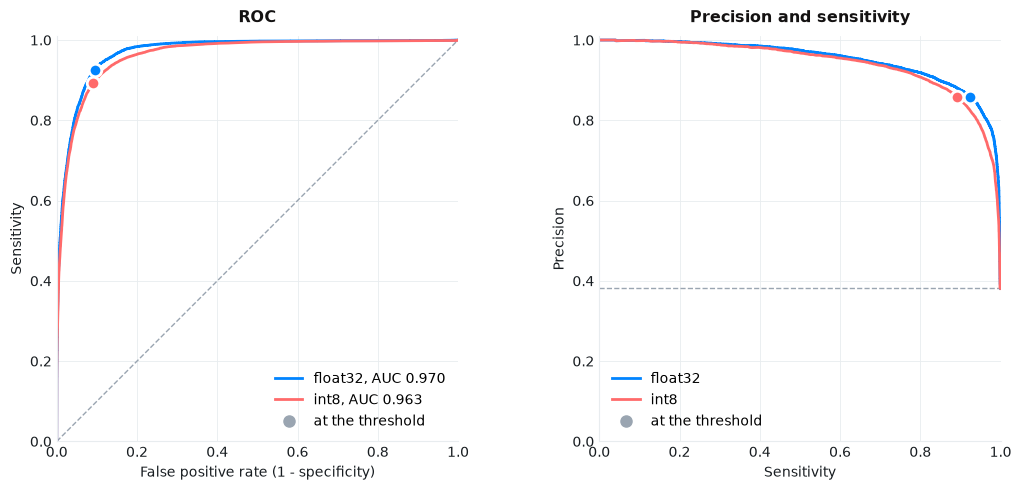

In [6]:
fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(11, 5))
roc_ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
pr_ax.axhline(y.mean(), color=MUTED, linestyle="--", linewidth=1)
for model in MODELS:
    s = results[model]["all 70 nights"]
    fpr, tpr, _ = roc_curve(y, prob[model])
    precision, recall, _ = precision_recall_curve(y, prob[model])
    roc_ax.plot(fpr, tpr, color=COLORS[model], label=f"{NAMES[model]}, AUC {s['auc']:.3f}")
    pr_ax.plot(recall, precision, color=COLORS[model], label=NAMES[model])
    for ax, point in ((roc_ax, (1 - s["specificity"], s["sensitivity"])),
                      (pr_ax, (s["sensitivity"], s["precision"]))):
        ax.plot(*point, "o", markersize=9, color=COLORS[model], markeredgecolor=SURFACE,
                markeredgewidth=2, zorder=3)
for ax in (roc_ax, pr_ax):
    ax.plot([], [], "o", markersize=8, color=MUTED, label="at the threshold")
    # An empty series: only adds the dot to the legend.
roc_ax.set(title="ROC", xlabel="False positive rate (1 - specificity)", ylabel="Sensitivity",
           xlim=(0, 1), ylim=(0, 1.01), aspect="equal")
pr_ax.set(title="Precision and sensitivity", xlabel="Sensitivity", ylabel="Precision",
          xlim=(0, 1), ylim=(0, 1.01), aspect="equal")
roc_ax.legend(loc="lower right")
pr_ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(OUT_DIR / "roc_pr.png")
plt.show()

## Threshold

Accuracy, sensitivity and specificity of all 70 nights at every threshold from 0.01 to 0.99. The
dots are the service's thresholds. The cell also prints the threshold with the
highest accuracy on Apnea-ECG itself; that one is picked with the expert's answers in hand, so its
accuracy is a ceiling, not a test score.

float32  threshold 0.41: accuracy 91.3%    highest on Apnea-ECG: 91.4% at 0.43
int8     threshold 0.51: accuracy 90.3%    highest on Apnea-ECG: 90.3% at 0.53


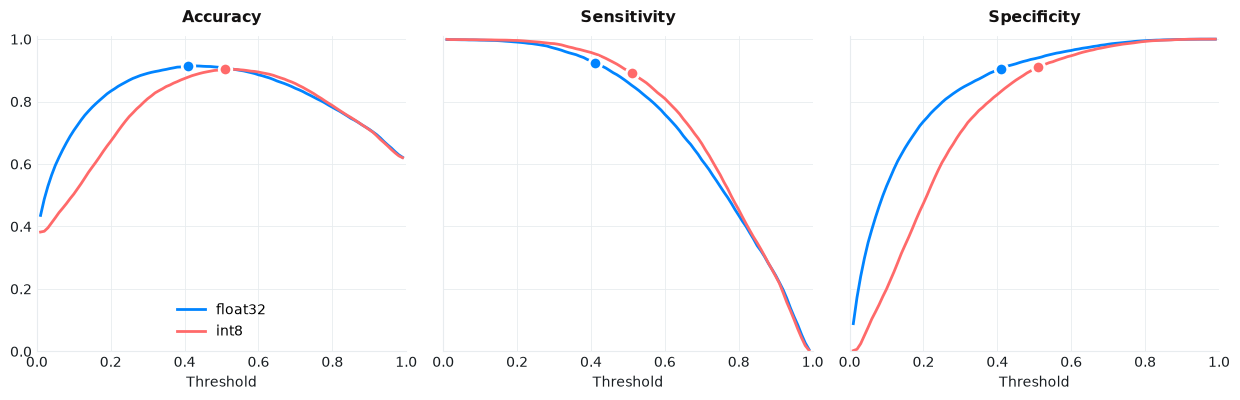

In [7]:
GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)      # the thresholds tried
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.1), sharey=True)
for model, threshold in MODELS.items():
    called = prob[model][:, np.newaxis] > GRID       # (minutes, thresholds): True = called apnea
    curves = {"Accuracy": (called == y[:, np.newaxis]).mean(axis=0),
              "Sensitivity": called[y == 1].mean(axis=0),
              "Specificity": 1 - called[y == 0].mean(axis=0)}
    k = int(np.argmin(np.abs(GRID - threshold)))     # the model's threshold within GRID
    for ax, (title, values) in zip(axes, curves.items()):
        ax.plot(GRID, values, color=COLORS[model], label=NAMES[model])
        ax.plot(threshold, values[k], "o", markersize=9, color=COLORS[model], markeredgecolor=SURFACE,
                markeredgewidth=2, zorder=3)
        ax.set(title=title, xlabel="Threshold", xlim=(0, 1), ylim=(0, 1.01))
    best = int(np.argmax(curves["Accuracy"]))
    print(f"{NAMES[model]:8s} threshold {threshold:.2f}: accuracy {curves['Accuracy'][k]:.1%}    "
          f"highest on Apnea-ECG: {curves['Accuracy'][best]:.1%} at {GRID[best]:.2f}")
axes[0].legend(loc="lower center")
fig.tight_layout()
fig.savefig(OUT_DIR / "thresholds.png")
plt.show()

## One night

One night minute by minute: the expert's apnea minutes, each model's, and the smoothed
probabilities behind the models' decisions, with each model's threshold dashed. The thin line is
the float32 model's probability before smoothing. `EXAMPLE_NIGHT` can be any of the 70 records.

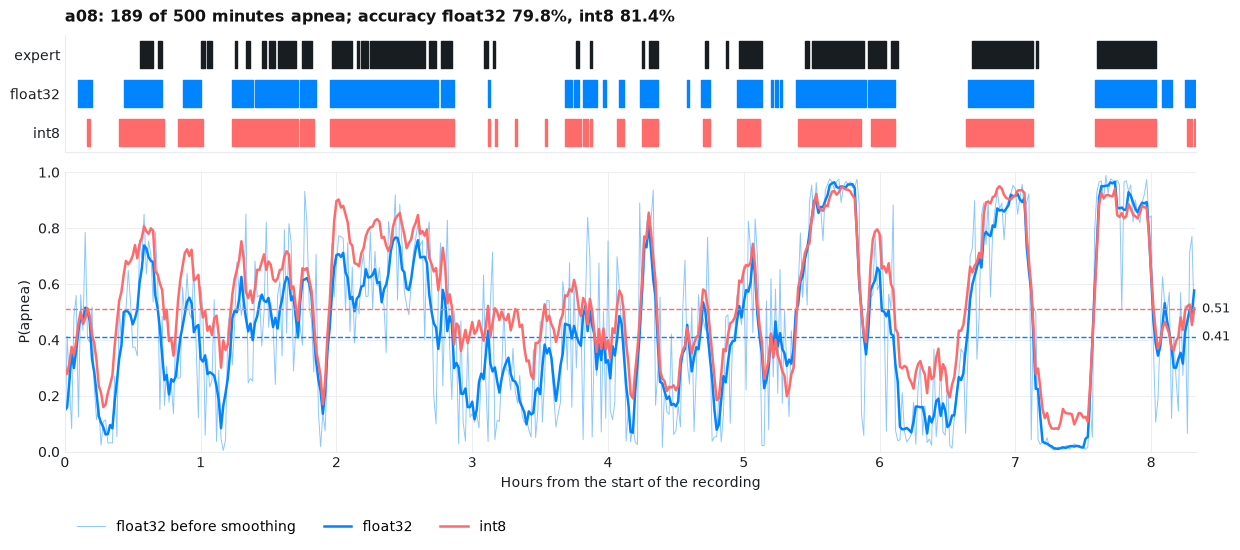

In [8]:
EXAMPLE_NIGHT = "a08"
f32 = MODEL_FILES[0]   # the float32 model, whose probability before smoothing is drawn too

i = nights.index(EXAMPLE_NIGHT)
rows = night == i
accuracy = {m: results[m]["per night"][EXAMPLE_NIGHT]["accuracy"] for m in MODELS}
hours = np.arange(rows.sum()) / 60
# A night's rows are its labelled minutes in order, from the recording's
# first minute; minute m is at m / 60 hours.


def runs(mask: np.ndarray) -> list[tuple[float, float]]:
    edges = np.flatnonzero(np.diff(np.concatenate([[0], mask, [0]])))
    return [(a / 60, (b - a) / 60) for a, b in zip(edges[::2], edges[1::2])]
    # Consecutive apnea minutes -> one (start, length) pair in hours: the
    # mask's rises and falls, read two at a time.


fig, (strip_ax, prob_ax) = plt.subplots(2, 1, figsize=(12.5, 5.6), sharex=True, height_ratios=[1, 2.4])
lanes = [("expert", y[rows], INK_2)] + [(NAMES[m], apnea[m][rows], COLORS[m]) for m in MODELS]
for k, (label, mask, color) in enumerate(lanes):
    strip_ax.broken_barh(runs(mask), (k - 0.35, 0.7), color=color)
strip_ax.set_yticks(range(len(lanes)), [label for label, *_ in lanes])
strip_ax.set_ylim(len(lanes) - 0.5, -0.5)
strip_ax.grid(False)
strip_ax.set_title(f"{EXAMPLE_NIGHT}: {expert_minutes[i]} of {rows.sum()} minutes apnea; accuracy "
                   + ", ".join(f"{NAMES[m]} {accuracy[m]:.1%}" for m in MODELS), loc="left")

prob_ax.plot(hours, raw[f32][rows], color=COLORS[f32], linewidth=0.7, alpha=0.45,
             label=f"{NAMES[f32]} before smoothing")
for m, threshold in MODELS.items():
    prob_ax.plot(hours, prob[m][rows], color=COLORS[m], linewidth=1.8, label=NAMES[m])
    prob_ax.axhline(threshold, color=COLORS[m], linestyle="--", linewidth=1)
    prob_ax.annotate(f"{threshold:.2f}", (1, threshold), xycoords=("axes fraction", "data"),
                     xytext=(4, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
prob_ax.set(xlabel="Hours from the start of the recording", ylabel="P(apnea)", ylim=(0, 1),
            xlim=(0, len(hours) / 60))
prob_ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncols=3)
fig.tight_layout()
fig.savefig(OUT_DIR / "example_night.png")
plt.show()